# Heart Failure Prediction — Análise, treinamento e exportação de uma MLP

Este notebook documenta o ciclo de modelagem de um classificador de rede neural multicamadas (MLP) para indicar a **presença ou ausência de indicativos de doença cardíaca** a partir de características clínicas.

**Finalidade:** exclusivamente acadêmica e demonstrativa. O modelo **não é uma ferramenta de diagnóstico médico** e não deve ser utilizado para decisões clínicas.

## Contexto do problema

A doença cardiovascular é uma das principais causas de morbidade e mortalidade. Identificar precocemente pacientes com maior probabilidade de apresentar doença cardíaca, a partir de exames e dados clínicos de rotina, é uma tarefa em que modelos preditivos podem apoiar a triagem, desde que interpretados com cautela pelos profissionais de saúde.

**Origem do dataset:** *Heart Failure Prediction Dataset*, publicado no Kaggle por fedesoriano.
Link: https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction

**Objetivo de Aprendizagem de Máquina:** dado o conjunto de atributos clínicos de um paciente, prever a variável binária `HeartDisease` (classificação binária).

**Variável alvo (`HeartDisease`):**
- `0` = ausência de doença cardíaca;
- `1` = presença de doença cardíaca.

A coluna `HeartDisease` **não** é utilizada como entrada do modelo.

## Dicionário de dados

| Coluna | Tipo | Significado prático |
|---|---|---|
| `Age` | Numérico | Idade do paciente, em anos |
| `Sex` | Categórico | Sexo do paciente (`M` = masculino, `F` = feminino) |
| `ChestPainType` | Categórico | Tipo de dor no peito: `TA` = angina típica, `ATA` = angina atípica, `NAP` = dor não anginosa, `ASY` = assintomático |
| `RestingBP` | Numérico | Pressão arterial em repouso (mm Hg) |
| `Cholesterol` | Numérico | Nível de colesterol sérico (mg/dl) |
| `FastingBS` | Numérico (binário) | Glicemia em jejum acima de 120 mg/dl: `1` = sim, `0` = não |
| `RestingECG` | Categórico | Resultado do eletrocardiograma em repouso: `Normal`, `ST` (anomalia de onda ST-T) ou `LVH` (hipertrofia ventricular esquerda provável) |
| `MaxHR` | Numérico | Frequência cardíaca máxima atingida durante o teste (bpm) |
| `ExerciseAngina` | Categórico | Angina induzida por exercício: `Y` = sim, `N` = não |
| `Oldpeak` | Numérico | Depressão do segmento ST induzida por exercício, em relação ao repouso |
| `ST_Slope` | Categórico | Inclinação do segmento ST no pico do exercício: `Up`, `Flat` ou `Down` |
| `HeartDisease` | Alvo (binário) | Presença de doença cardíaca: `1` = sim, `0` = não |

## 1. Análise exploratória resumida

Nesta seção verificamos a dimensionalidade, os tipos de dados, a presença de valores ausentes e duplicados, a distribuição da variável alvo e o comportamento dos atributos numéricos.

In [1]:
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, matthews_corrcoef
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sns.set_theme(style="whitegrid")
RANDOM_STATE = 77

# Caminhos relativos à raiz do projeto (funciona ao executar a partir de notebooks/ ou da raiz)
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "heart.csv"
MODEL_PATH = ROOT / "models" / "pipeline_rede_neural.joblib"

df = pd.read_csv(DATA_PATH)
display(df.head())

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [2]:
print("Dimensões (linhas, colunas):", df.shape)
print()
df.info()
print()
display(df.describe().T)
print()
print("Valores nulos por coluna:")
print(df.isnull().sum())
print()
print("Registros duplicados:", df.duplicated().sum())

Dimensões (linhas, colunas): (918, 12)

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB



,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0



Valores nulos por coluna:
Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64

Registros duplicados: 0


Contagem da variável alvo:
HeartDisease
Sem doença (0)    410
Com doença (1)    508
Name: count, dtype: int64

Proporção:
HeartDisease
Sem doença (0)    0.447
Com doença (1)    0.553
Name: count, dtype: float64


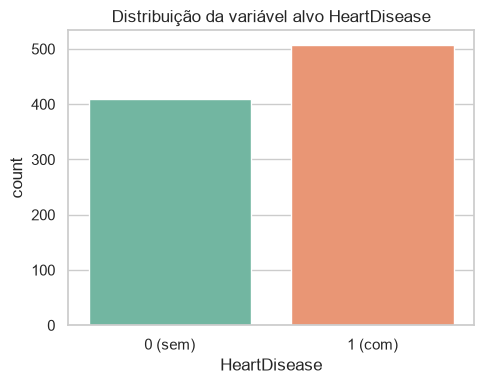

In [3]:
contagem = df["HeartDisease"].value_counts().sort_index()
print("Contagem da variável alvo:")
print(contagem.rename({0: "Sem doença (0)", 1: "Com doença (1)"}))
print()
print("Proporção:")
print((contagem / contagem.sum()).round(3).rename({0: "Sem doença (0)", 1: "Com doença (1)"}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="HeartDisease", hue="HeartDisease", palette="Set2", legend=False, ax=ax)
ax.set_title("Distribuição da variável alvo HeartDisease")
ax.set_xlabel("HeartDisease")
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 (sem)", "1 (com)"])
plt.tight_layout()
plt.show()

In [4]:
zeros = {
    "RestingBP": int((df["RestingBP"] == 0).sum()),
    "Cholesterol": int((df["Cholesterol"] == 0).sum()),
}
print("Registros com valor igual a zero (potencialmente atípicos ou ausentes):")
for coluna, total in zeros.items():
    print(f"  {coluna}: {total}")
print()
print("Registro com RestingBP = 0:")
display(df.loc[df["RestingBP"] == 0])

Registros com valor igual a zero (potencialmente atípicos ou ausentes):
  RestingBP: 1
  Cholesterol: 172

Registro com RestingBP = 0:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
449,55,M,NAP,0,0,0,Normal,155,N,1.5,Flat,1


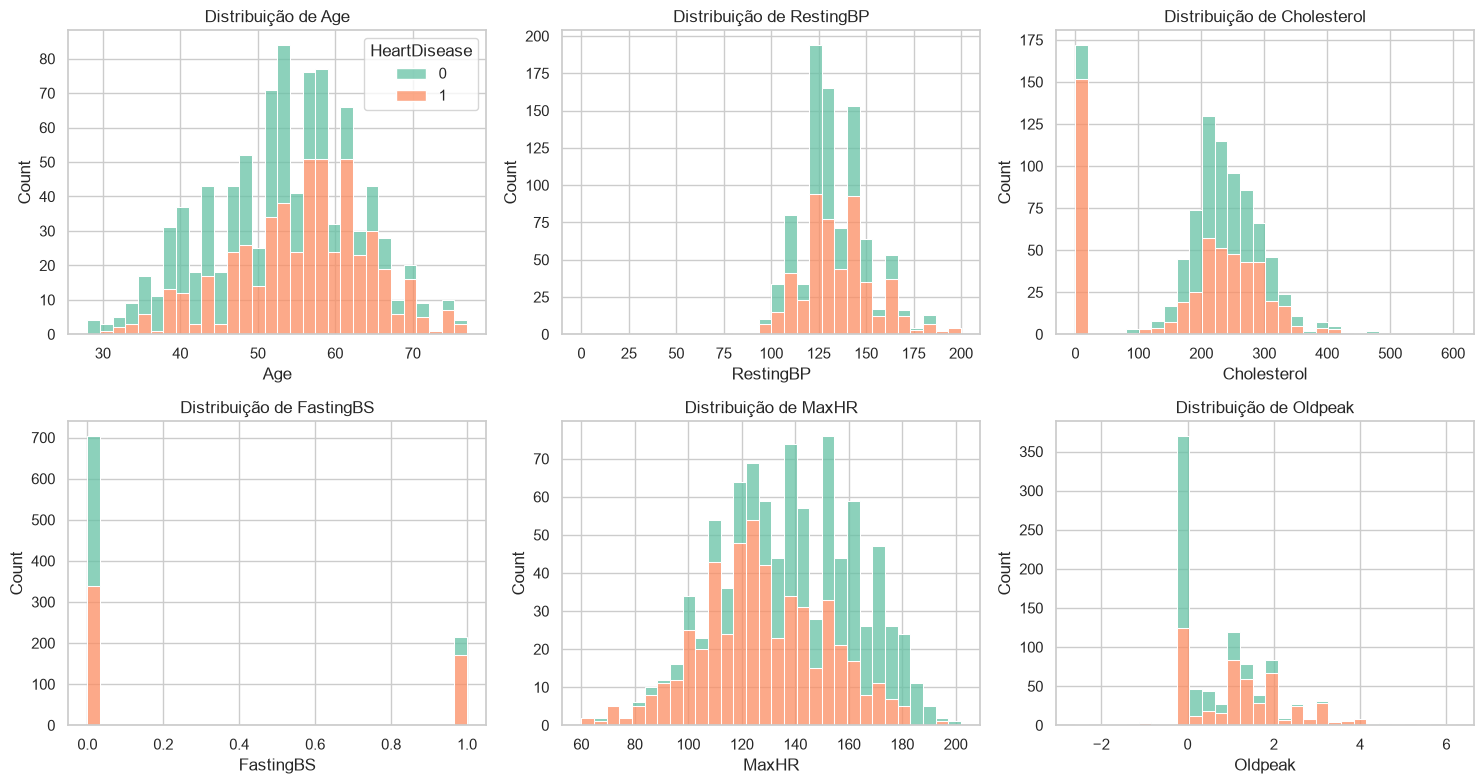

In [5]:
colunas_numericas = ["Age", "RestingBP", "Cholesterol", "FastingBS", "MaxHR", "Oldpeak"]

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for ax, coluna in zip(eixos.ravel(), colunas_numericas):
    sns.histplot(data=df, x=coluna, hue="HeartDisease", bins=30, multiple="stack",
                 palette="Set2", ax=ax, legend=(coluna == "Age"))
    ax.set_title(f"Distribuição de {coluna}")
plt.tight_layout()
plt.show()

### Observações da análise exploratória

- **Dimensionalidade:** o dataset possui 918 registros e 12 colunas (11 preditoras e a variável alvo), atendendo ao mínimo de registros e de atributos exigidos.
- **Valores ausentes e duplicados:** não há valores nulos nem registros duplicados. Os tipos foram lidos corretamente: 6 colunas numéricas inteiras, 1 numérica decimal (`Oldpeak`) e 5 categóricas.
- **Balanceamento da variável alvo:** há 508 registros com doença (55,3%) e 410 sem (44,7%). O desbalanceamento é leve, por isso não foram aplicadas técnicas específicas de reamostragem; a métrica de Matthews será útil para avaliar o desempenho de forma equilibrada.
- **Zeros atípicos:** `RestingBP` possui 1 registro com valor 0, e `Cholesterol` possui 172 registros com valor 0. Valores zero de pressão arterial e colesterol são fisiologicamente implausíveis, e é provável que representem dados ausentes codificados como zero. **Esses valores não foram removidos nem imputados automaticamente**, conforme as orientações da atividade; essa limitação é documentada e será discutida ao final.
- **Faixas de valores:** `Age` varia de 28 a 77 anos; `MaxHR` de 60 a 202 bpm; `Oldpeak` de -2,6 a 6,2. Essas faixas são compatíveis com os limites de validação definidos para a API.

## 2. Preparação dos dados

Separamos as variáveis preditoras (`X`) e a variável alvo (`y`). As colunas numéricas e categóricas são identificadas automaticamente pelo tipo de dado. A coluna `FastingBS`, embora binária, é numérica e recebe o mesmo tratamento das demais variáveis numéricas.

A divisão treino/teste utiliza `test_size=0.20`, `random_state=77` e `stratify=y`, preservando a proporção da classe alvo nos dois conjuntos.

In [6]:
X = df.drop(columns="HeartDisease")
y = df["HeartDisease"]

colunas_num = X.select_dtypes(include="number").columns.tolist()
colunas_cat = X.select_dtypes(exclude="number").columns.tolist()
print("Colunas numéricas:  ", colunas_num)
print("Colunas categóricas:", colunas_cat)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print()
print("Treino:", X_train.shape, "| Teste:", X_test.shape)
print("Proporção de positivos no treino:", round(y_train.mean(), 3))
print("Proporção de positivos no teste: ", round(y_test.mean(), 3))

Colunas numéricas:   ['Age', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'Oldpeak']
Colunas categóricas: ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

Treino: (734, 11) | Teste: (184, 11)
Proporção de positivos no treino: 0.553
Proporção de positivos no teste:  0.554


## 3. Construção do Pipeline

O pipeline reúne todo o pré-processamento e o estimador em um único objeto:

- **Colunas numéricas:** `StandardScaler`, que centraliza e escala cada atributo com média e desvio padrão aprendidos apenas no treino.
- **Colunas categóricas:** `OneHotEncoder(handle_unknown="ignore")`, que cria uma coluna binária por categoria. Com `handle_unknown="ignore"`, categorias não vistas no treino não interrompem a inferência.
- **Estimador:** `MLPClassifier` com duas camadas ocultas, `(64, 32)`, ativação ReLU, otimizador Adam, taxa de aprendizado inicial de 0,001, até 1000 iterações, parada antecipada (`early_stopping=True`) e `random_state=77`.

Como o pipeline é treinado somente com os dados de treino, o `StandardScaler` e o `OneHotEncoder` não têm acesso às estatísticas do conjunto de teste, evitando vazamento de dados.

In [7]:
preprocessador = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), colunas_num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), colunas_cat),
    ]
)

mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=1000,
    random_state=RANDOM_STATE,
    early_stopping=True,
)

pipeline = Pipeline(steps=[("preprocessor", preprocessador), ("mlp", mlp)])
print(pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('mlp',
                 MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32),
                               max_iter=1000, random_state=77))])


## 4. Treinamento e avaliação

Treinamos o pipeline completo com os dados de treino e avaliamos as previsões sobre os dados de teste, que não participaram do treinamento. Também verificamos se houve avisos de convergência.

In [8]:
with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    pipeline.fit(X_train, y_train)

avisos_convergencia = [a for a in avisos if "converge" in str(a.message).lower()]
mlp_treinada = pipeline.named_steps["mlp"]
print("Iterações executadas:", mlp_treinada.n_iter_, "de no máximo", mlp_treinada.max_iter)
print("Avisos de convergência:", len(avisos_convergencia))

Iterações executadas: 23 de no máximo 1000
Avisos de convergência: 0


In [9]:
y_pred = pipeline.predict(X_test)

print(f"Acurácia global: {accuracy_score(y_test, y_pred):.4f}")
print()
print("Relatório de classificação:")
print(classification_report(
    y_test, y_pred,
    target_names=["Sem indicativo (0)", "Com indicativo (1)"],
    digits=4,
))
print(f"Coeficiente de correlação de Matthews (MCC): {matthews_corrcoef(y_test, y_pred):.4f}")

Acurácia global: 0.8315

Relatório de classificação:
                    precision    recall  f1-score   support

Sem indicativo (0)     0.8228    0.7927    0.8075        82
Com indicativo (1)     0.8381    0.8627    0.8502       102

          accuracy                         0.8315       184
         macro avg     0.8304    0.8277    0.8288       184
      weighted avg     0.8313    0.8315    0.8312       184

Coeficiente de correlação de Matthews (MCC): 0.6581


Verdadeiros negativos: 65 | Falsos positivos: 17
Falsos negativos:      14 | Verdadeiros positivos: 88


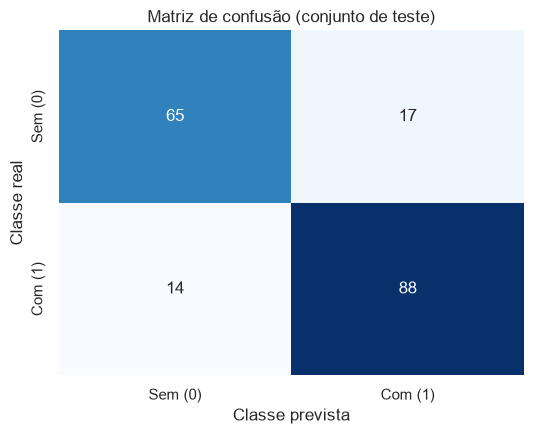

In [10]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"Verdadeiros negativos: {tn} | Falsos positivos: {fp}")
print(f"Falsos negativos:      {fn} | Verdadeiros positivos: {tp}")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
    xticklabels=["Sem (0)", "Com (1)"], yticklabels=["Sem (0)", "Com (1)"],
)
ax.set_xlabel("Classe prevista")
ax.set_ylabel("Classe real")
ax.set_title("Matriz de confusão (conjunto de teste)")
plt.tight_layout()
plt.show()

### Interpretação dos resultados

Os valores abaixo foram calculados na execução deste notebook, sobre os 184 registros do conjunto de teste.

- **Acurácia global de 0,8315:** o modelo acertou 153 de 184 casos.
- **Relatório por classe:** para a classe `1` (com indicativo), o *recall* de 0,8627 indica que o modelo identificou a maior parte dos pacientes que de fato apresentam o alvo. Para a classe `0`, o *recall* é de 0,7927. A precisão da classe `1` (0,8381) mostra que, entre os casos previstos como positivos, a maioria está correta.
- **Coeficiente de Matthews de 0,6581:** por considerar todos os quadrantes da matriz de confusão, esse valor indica uma concordância substancial entre previsões e realidade, mesmo com o leve desbalanceamento da classe alvo.
- **Matriz de confusão:** a matriz registra 17 falsos positivos (pacientes sem indicativo classificados como com indicativo) e 14 falsos negativos (pacientes com indicativo classificados como sem). Em um contexto de triagem, os falsos negativos são os mais sensíveis, porque deixam de sinalizar um caso positivo; já os falsos positivos geram triagens desnecessárias.

Como o conjunto de teste contém apenas 184 registros, essas métricas têm variabilidade natural; um conjunto de teste maior ou validação cruzada forneceriam uma estimativa mais robusta, o que não foi escopo desta etapa.

## 5. Exportação do modelo

Salvamos o **pipeline completo**, incluindo o `ColumnTransformer` e o `MLPClassifier`. Assim, as médias e desvios aprendidos pelo `StandardScaler` e as categorias aprendidas pelo `OneHotEncoder` ficam armazenados junto com a rede. A API poderá receber os dados brutos e aplicar exatamente o mesmo pré-processamento usado no treinamento.

In [11]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(pipeline, MODEL_PATH)
print("Pipeline salvo em:", MODEL_PATH.relative_to(ROOT))

# Verificação: o pipeline recarregado deve produzir exatamente as mesmas previsões
pipeline_recarregado = joblib.load(MODEL_PATH)
previsoes_recarregadas = pipeline_recarregado.predict(X_test)
print("Previsões idênticas após recarregar:", bool((previsoes_recarregadas == y_pred).all()))

Pipeline salvo em: models\pipeline_rede_neural.joblib
Previsões idênticas após recarregar: True


## 6. Limitações do dataset e do estudo

- **Valores zero em `RestingBP` e `Cholesterol`:** há registros com valor 0 em atributos que não deveriam assumir esse valor. Eles foram mantidos sem alteração, conforme o critério de não remover ou imputar dados sem justificativa. Não foi avaliado isoladamente o impacto desses registros no desempenho do modelo.
- **Tamanho da amostra:** com 918 registros e um conjunto de teste de 184, as métricas apresentam variabilidade; os resultados devem ser lidos como estimativas de um único experimento.
- **Origem dos dados:** o dataset combina registros de diferentes bases; a generalização para outras populações ou serviços de saúde não é garantida.
- **Uso:** o modelo é uma demonstração acadêmica de aprendizagem de máquina e de deploy de API. Não substitui avaliação médica.